# Phase 2 — Feature Selection

**Follows:** `02_features_split.ipynb` (36 default features, plus held-back user snapshot and `merchant_state` features).

**Scope:** rank the default features with four common techniques for tabular fraud data, combine the votes, and check that the reduced set doesn't lose performance.

| # | Technique | Family | Question it answers |
|---|---|---|---|
| 1 | Correlation + mutual information | Filter | Is the feature redundant? Does it carry *any* information about fraud on its own? |
| 2 | L1 (Lasso) logistic regression | Embedded, linear | Does a sparse linear model need it? |
| 3 | CatBoost importance | Embedded, trees | How much does a boosted-tree model rely on it? |
| 4 | Permutation importance on validation | Model-agnostic | Does shuffling it hurt PR-AUC on **unseen** data? |

**Rules:**
- Only **train (≤2017)** and **validation (2018)** are used. The 2019 test set is never loaded.
- Fitting uses an undersampled training set (every fraud plus a random sample of non-frauds). Validation keeps its real class balance, because PR-AUC depends on it.
- `merchant_state` and the user snapshots are **not** selection candidates. Whether to use them is decided by ablation (section 6 has a preview), not by importance scores they'd inflate.

## 0. Setup

In [1]:
import sys, json, time, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.inspection import permutation_importance
from catboost import CatBoostClassifier

from src import features as F
from src.data import CACHE_DIR, PROJECT_ROOT
from src.modeling import (TARGET, load_split, undersample, linear_preprocessor,
                          catboost_frame, categorical_in, source_feature)

sns.set_style("whitegrid")
pd.set_option("display.max_columns", 40)
SEED = 0

CANDIDATES = F.DEFAULT_FEATURES
HELD_BACK = F.SHORTCUT_FEATURES + F.USER_SNAPSHOT_FEATURES
print(f"{len(CANDIDATES)} candidate features; held back for ablation: {HELD_BACK}")

36 candidate features; held back for ablation: ['merchant_state', 'user_age', 'user_income', 'user_debt', 'fico_score', 'num_credit_cards']


In [2]:
train = load_split("train", CANDIDATES + HELD_BACK)
val = load_split("val", CANDIDATES + HELD_BACK)

# One undersampled training set (1 fraud : 10 non-fraud) shared by every method,
# so differences between methods come from the method, not the sample.
sel = undersample(train, neg_per_pos=10, seed=SEED)
y_sel, y_val = sel[TARGET], val[TARGET]

print(f"train: {len(train):,} rows  ->  selection sample: {len(sel):,} rows ({y_sel.mean():.1%} fraud)")
print(f"val:   {len(val):,} rows ({y_val.mean():.3%} fraud, real balance)")
print(f"PR-AUC of a random model on val = fraud rate = {y_val.mean():.4f}")

train: 20,604,847 rows  ->  selection sample: 276,969 rows (9.1% fraud)
val:   1,721,615 rows (0.145% fraud, real balance)
PR-AUC of a random model on val = fraud rate = 0.0014


## 1. Filter methods

### 1.1 Near-constant features

🎯 **Goal:** find features that almost never change.

💡 **Why not just drop them?** In fraud data a rare flag can be the most valuable feature: if `err_bad_zipcode` fires on 0.01% of rows but those rows are 20× more likely to be fraud, it matters. So check each rare feature's fraud lift before judging it.

In [3]:
base = train[TARGET].mean()
rows = []
for f in CANDIDATES:
    top_share = train[f].value_counts(normalize=True, dropna=False).iloc[0]
    if top_share > 0.995:
        rare = train[f] != train[f].mode().iloc[0]
        rows.append({"feature": f, "most_common_share": round(top_share, 5),
                     "rows_with_other_values": int(rare.sum()),
                     "fraud_lift_when_other": round(train.loc[rare, TARGET].mean() / base, 1)})
near_constant = pd.DataFrame(rows).sort_values("most_common_share", ascending=False)
near_constant

,feature,most_common_share,rows_with_other_values,fraud_lift_when_other
6,err_bad_zipcode,0.99991,1784,0.0
4,err_bad_cvv,0.99956,9115,25.6
5,err_bad_expiration,0.99956,9053,11.2
3,err_bad_card_number,0.99946,11228,7.8
0,is_zero_amount,0.99917,17205,0.3
2,err_technical_glitch,0.99800,41136,1.1
1,err_bad_pin,0.99755,50485,3.2


### 1.2 Redundancy: Spearman correlation

🎯 **Goal:** find pairs of features that carry the same information.

💡 Spearman (rank correlation) is used because most features are skewed counts and amounts. Redundant features don't hurt boosted trees much, but they make linear coefficients unstable and split importance arbitrarily between the pair. That's also why SHAP values get harder to read later.

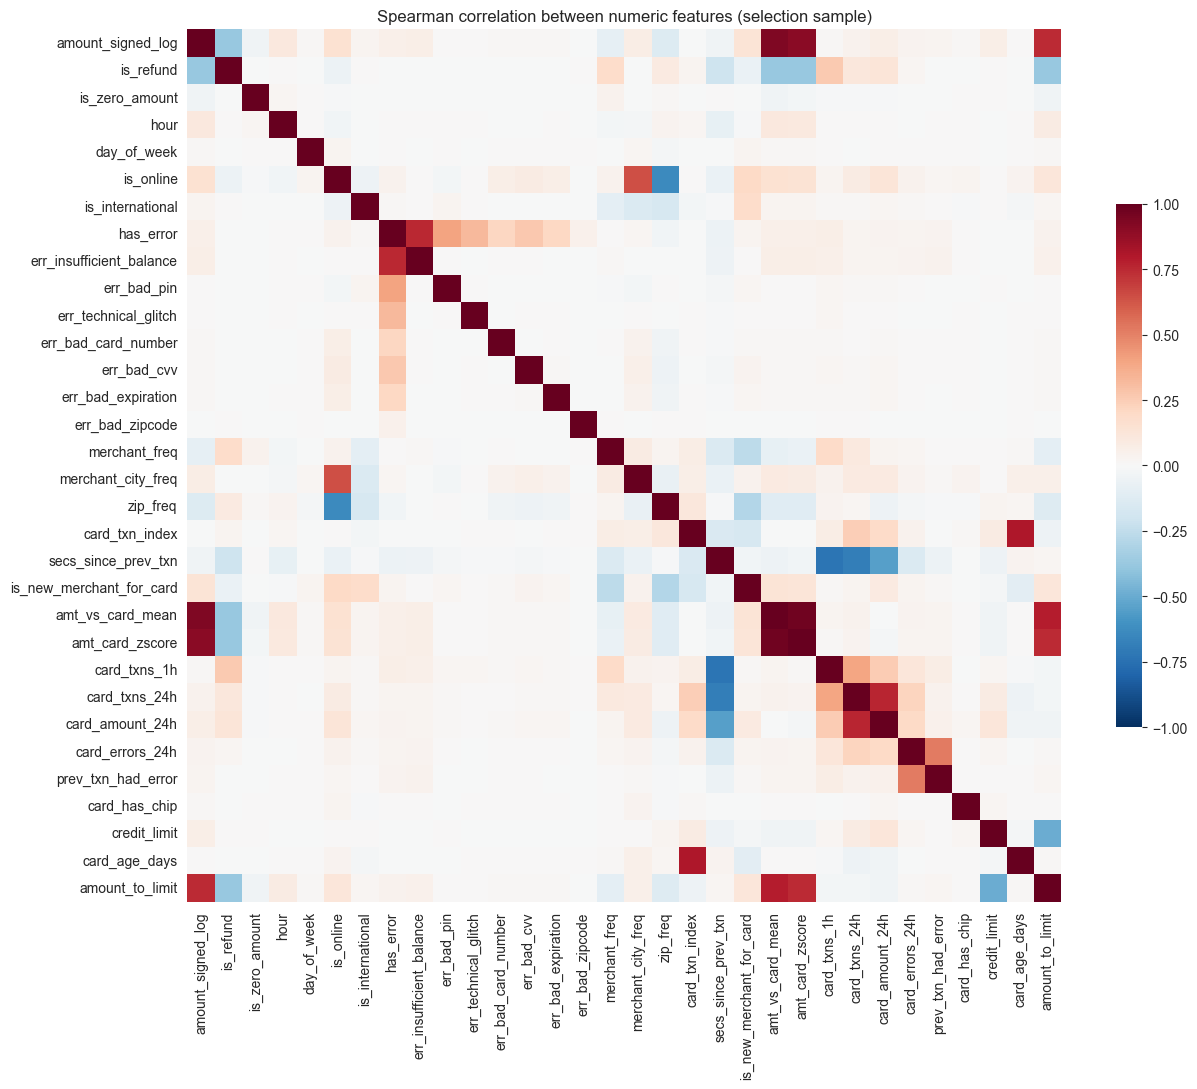

,feature_a,feature_b,spearman
441,amt_vs_card_mean,amt_card_zscore,0.971240
20,amount_signed_log,amt_vs_card_mean,0.934061
21,amount_signed_log,amt_card_zscore,0.902112


In [4]:
numeric = [f for f in CANDIDATES if f not in categorical_in(CANDIDATES)]
corr = sel[numeric].corr(method="spearman")

pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
             .stack().rename("spearman").reset_index()
             .rename(columns={"level_0": "feature_a", "level_1": "feature_b"}))
redundant_pairs = pairs[pairs["spearman"].abs() > 0.9].sort_values("spearman", key=abs, ascending=False)

fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, cbar_kws={"shrink": 0.6})
ax.set_title("Spearman correlation between numeric features (selection sample)")
plt.tight_layout()
plt.show()
redundant_pairs

### 1.3 Mutual information

🎯 **Goal:** measure how much each feature *alone* tells us about fraud, including non-linear relationships that correlation misses.

💡 **Limitation:** MI looks at one feature at a time. A feature that only matters in combination (e.g. amount *relative to* the card's history) can score low. That's why it's one vote of four, not the decision.

MI computed on 100,716 rows in 3s


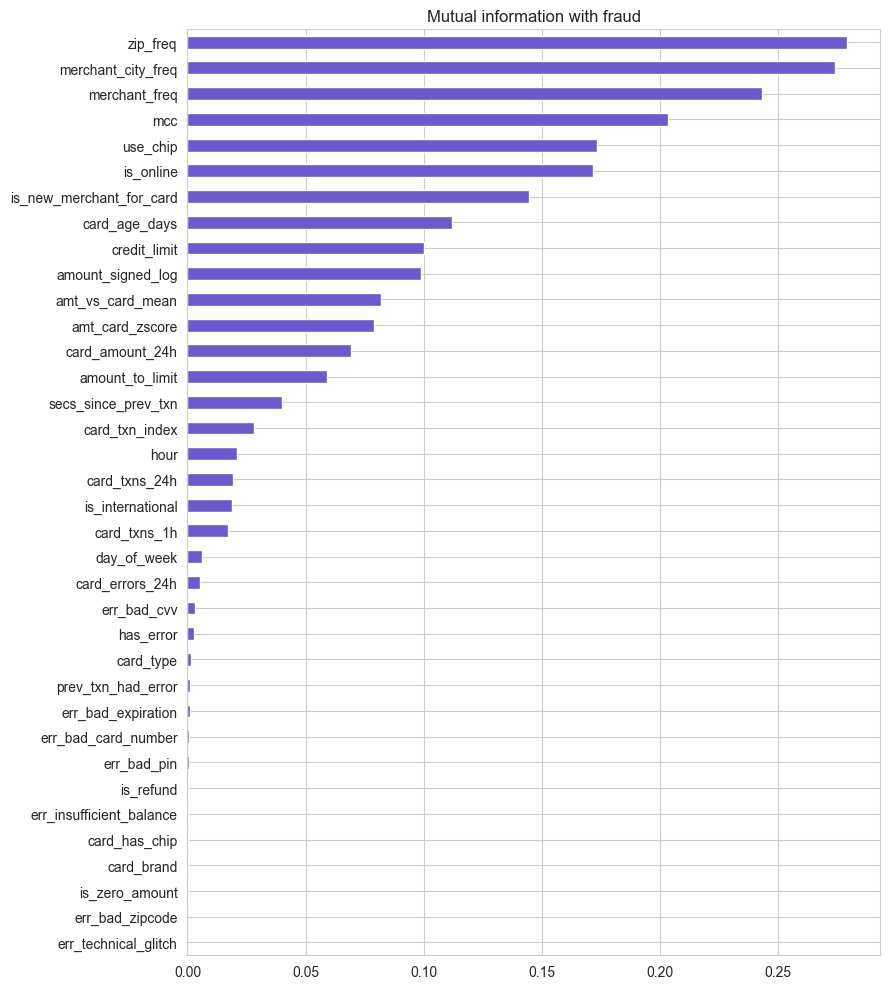

In [5]:
mi_sample = undersample(train, neg_per_pos=3, seed=SEED)   # kNN-based MI is slow; 100k rows is plenty
X_mi = mi_sample[CANDIDATES].copy()
for c in categorical_in(CANDIDATES):
    X_mi[c] = X_mi[c].cat.codes
X_mi = X_mi.fillna(-1)
discrete = [c in categorical_in(CANDIDATES) or X_mi[c].nunique() <= 30 for c in CANDIDATES]

t0 = time.time()
mi = pd.Series(mutual_info_classif(X_mi, mi_sample[TARGET], discrete_features=discrete, random_state=SEED),
               index=CANDIDATES).sort_values(ascending=False)
print(f"MI computed on {len(mi_sample):,} rows in {time.time() - t0:.0f}s")

mi.plot(kind="barh", figsize=(9, 10), color="slateblue").invert_yaxis()
plt.title("Mutual information with fraud")
plt.tight_layout()
plt.show()

## 2. L1 (Lasso) logistic regression

🎯 **Goal:** let a linear model pick features. The L1 penalty pushes the weights of unhelpful features to exactly zero.

💡 **How to read it:** sweep the penalty strength `C` from strong (few features survive) to weak (most survive). Features that enter the model **earliest**, at the strongest penalty, are the ones it needs most. Inputs are standardized so the coefficients are comparable, and one-hot categories are grouped back to their source feature.

The model uses `class_weight="balanced"`, so the 1:10 sample is re-weighted to equal class importance.

In [6]:
pre = linear_preprocessor(CANDIDATES)
X_sel_lin = pre.fit_transform(sel[CANDIDATES])
X_val_lin = pre.transform(val[CANDIDATES])
encoded = pre.get_feature_names_out()
print(f"{len(CANDIDATES)} features -> {X_sel_lin.shape[1]} encoded columns")

C_GRID = [0.0003, 0.001, 0.003, 0.01, 0.03]
path_rows, coef_by_C = [], {}
for C in C_GRID:
    t0 = time.time()
    lr = LogisticRegression(l1_ratio=1, solver="liblinear", C=C, class_weight="balanced",
                            max_iter=1000, random_state=SEED).fit(X_sel_lin, y_sel)
    coefs = pd.Series(np.abs(lr.coef_[0]), index=encoded)
    by_feature = coefs.groupby([source_feature(n, CANDIDATES) for n in encoded]).max()
    coef_by_C[C] = by_feature
    path_rows.append({"C": C, "features_kept": int((by_feature > 0).sum()),
                      "val_pr_auc": round(average_precision_score(y_val, lr.predict_proba(X_val_lin)[:, 1]), 4),
                      "fit_s": round(time.time() - t0, 1)})
l1_path = pd.DataFrame(path_rows)
l1_path

36 features -> 125 encoded columns


,C,features_kept,val_pr_auc,fit_s
0,0.0003,14,0.0759,5.0
1,0.0010,24,0.0886,8.4
2,0.0030,24,0.1009,8.5
3,0.0100,32,0.1326,8.0
4,0.0300,32,0.1377,61.4


In [7]:
coef_table = pd.DataFrame(coef_by_C).reindex(CANDIDATES)
# Entry point: the strongest penalty at which the feature is already non-zero
entry_C = coef_table.gt(0).idxmax(axis=1).where(coef_table.gt(0).any(axis=1))

# Chosen C: the sparsest model within 5% of the best validation PR-AUC
best = l1_path["val_pr_auc"].max()
C_CHOSEN = l1_path.loc[l1_path["val_pr_auc"] >= 0.95 * best, "C"].min()
l1_kept = coef_table[C_CHOSEN] > 0
print(f"Chosen C = {C_CHOSEN}: keeps {l1_kept.sum()} of {len(CANDIDATES)} features")
print("Dropped by L1 at that C:", sorted(l1_kept[~l1_kept].index))

Chosen C = 0.01: keeps 32 of 36 features
Dropped by L1 at that C: ['err_bad_card_number', 'err_bad_zipcode', 'is_zero_amount', 'merchant_city_freq']


## 3. CatBoost importance

🎯 **Goal:** see which features a boosted-tree model actually splits on.

💡 CatBoost takes the categoricals (`mcc`, `use_chip`, card brand/type) natively. `PredictionValuesChange` measures how much the predictions move, on average, when a feature's splits are used.

**Caveat:** this is computed on the training sample, so it shows what the model *used*, not what *generalizes*. A feature can be used heavily to fit noise. Section 4 checks that on validation.

Fixed settings (500 trees, depth 6, no early stopping) keep validation clean for section 4. Tuning comes in a later phase.

Trained in 42s | validation PR-AUC (all 36 features): 0.7135


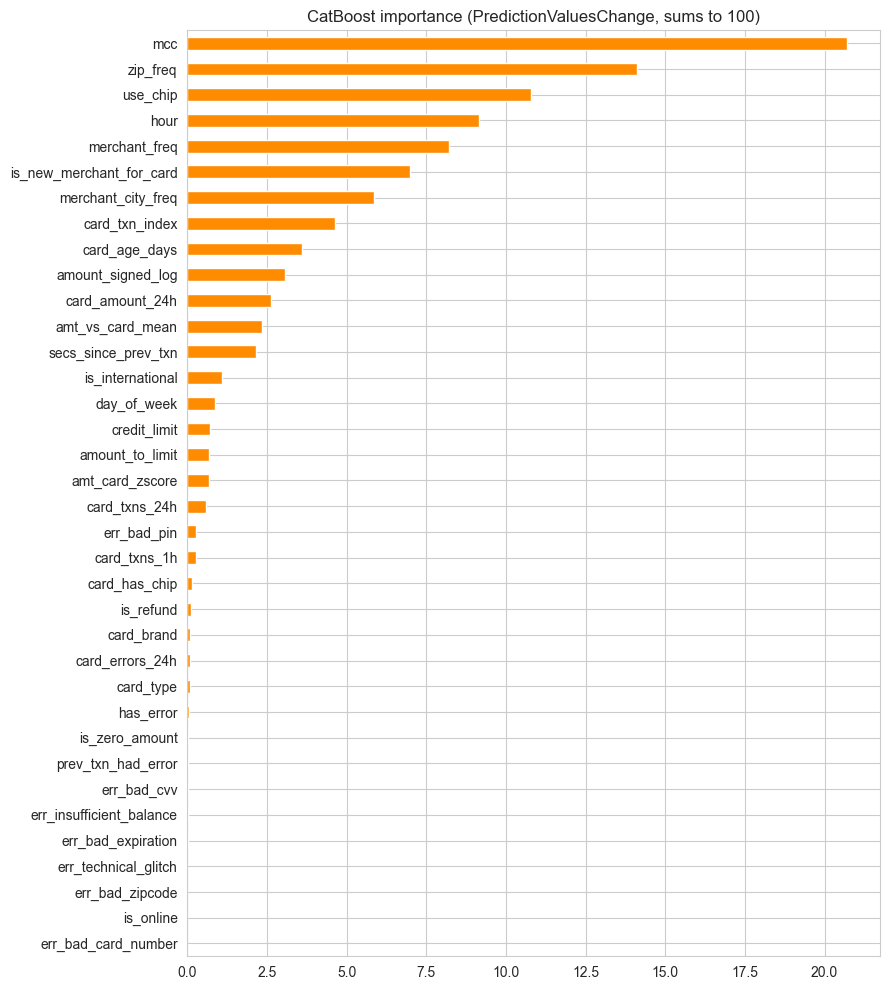

In [8]:
CB_PARAMS = dict(iterations=500, depth=6, learning_rate=0.1, random_seed=SEED,
                 verbose=0, thread_count=-1)

X_sel_cb = catboost_frame(sel, CANDIDATES)
X_val_cb = catboost_frame(val, CANDIDATES)
cats = categorical_in(CANDIDATES)

t0 = time.time()
cb = CatBoostClassifier(**CB_PARAMS).fit(X_sel_cb, y_sel, cat_features=cats)
p_val = cb.predict_proba(X_val_cb)[:, 1]
print(f"Trained in {time.time() - t0:.0f}s | validation PR-AUC (all {len(CANDIDATES)} features): "
      f"{average_precision_score(y_val, p_val):.4f}")

cb_imp = pd.Series(cb.get_feature_importance(type="PredictionValuesChange"),
                   index=CANDIDATES).sort_values(ascending=False)
cb_imp.plot(kind="barh", figsize=(9, 10), color="darkorange").invert_yaxis()
plt.title("CatBoost importance (PredictionValuesChange, sums to 100)")
plt.tight_layout()
plt.show()

## 4. Permutation importance on validation

🎯 **Goal:** the most honest test. Shuffle one feature in the **2018 validation data** and measure how much PR-AUC drops. If shuffling doesn't hurt, the model doesn't need the feature on unseen data.

💡 It's repeated 3 times with different shuffles, so we get a mean and a spread. A feature counts as useful only if the drop is clearly above zero (mean − 2·std > 0). Validation is used at its real class balance: all 1.7M rows.

**Caveat:** for correlated pairs, shuffling one leaves the other to cover for it, so both can look unimportant. That's why this is read together with section 1.2.

Permutation importance on 1,721,615 validation rows in 223s


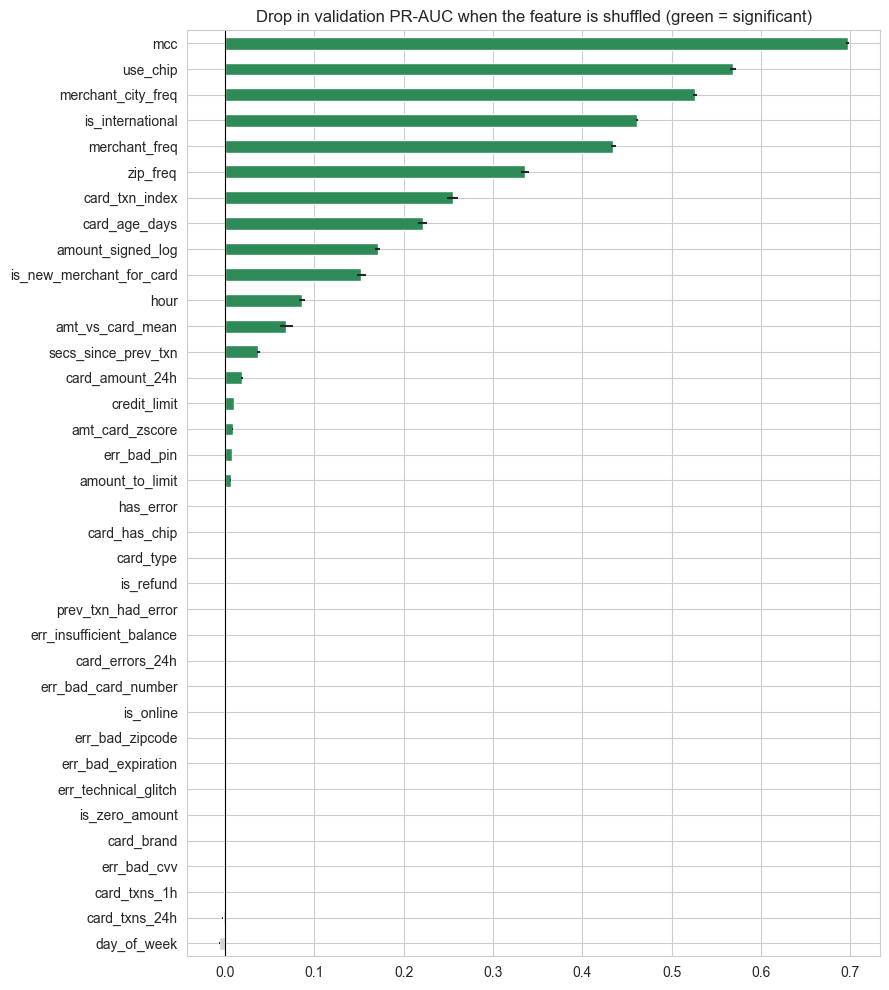

In [9]:
t0 = time.time()
perm = permutation_importance(cb, X_val_cb, y_val, scoring="average_precision",
                              n_repeats=3, random_state=SEED, n_jobs=1)
print(f"Permutation importance on {len(X_val_cb):,} validation rows in {time.time() - t0:.0f}s")

perm_df = (pd.DataFrame({"pr_auc_drop": perm.importances_mean, "std": perm.importances_std},
                        index=CANDIDATES).sort_values("pr_auc_drop", ascending=False))
perm_df["significant"] = perm_df["pr_auc_drop"] - 2 * perm_df["std"] > 0

ax = perm_df["pr_auc_drop"].plot(kind="barh", xerr=perm_df["std"], figsize=(9, 10),
                                 color=np.where(perm_df["significant"], "seagreen", "lightgray"))
ax.invert_yaxis()
ax.axvline(0, color="black", lw=0.8)
plt.title("Drop in validation PR-AUC when the feature is shuffled (green = significant)")
plt.tight_layout()
plt.show()

## 5. Combining the four methods

Each method votes a feature **weak** if:

| Method | Weak if |
|---|---|
| Mutual information | in the bottom quarter of MI scores |
| L1 logistic | coefficient is zero at the chosen C |
| CatBoost | importance below 0.5 (of 100) |
| Permutation | PR-AUC drop not significantly above 0 |

**Drop rule:** remove a feature if **at least 3 of the 4** methods call it weak. One method alone can be fooled: MI by interactions, L1 by non-linearity, CatBoost by overfitting, permutation by correlated partners. Agreement across different families is much harder to fake.

Redundant pairs (|Spearman| > 0.9) are listed too: if one member of a pair is weak in 2+ methods, it goes as well.

In [10]:
table = pd.DataFrame(index=CANDIDATES)
table["mutual_info"] = mi
table["l1_entry_C"] = entry_C
table["l1_kept"] = l1_kept
table["catboost_imp"] = cb_imp
table["perm_pr_auc_drop"] = perm_df["pr_auc_drop"]
table["perm_significant"] = perm_df["significant"]

weak = pd.DataFrame({
    "mi": table["mutual_info"] <= table["mutual_info"].quantile(0.25),
    "l1": ~table["l1_kept"].astype(bool),
    "catboost": table["catboost_imp"] < 0.5,
    "perm": ~table["perm_significant"].astype(bool),
})
table["weak_votes"] = weak.sum(axis=1)

# Redundancy: for each highly-correlated pair, the partner with lower permutation importance
redundant_with = {}
for _, r in redundant_pairs.iterrows():
    a, b = r["feature_a"], r["feature_b"]
    loser, winner = (a, b) if table.loc[a, "perm_pr_auc_drop"] < table.loc[b, "perm_pr_auc_drop"] else (b, a)
    redundant_with[loser] = winner
table["redundant_with"] = pd.Series(redundant_with)

table["decision"] = np.where(
    (table["weak_votes"] >= 3) | (table["redundant_with"].notna() & (table["weak_votes"] >= 2)),
    "drop", "keep")
table = table.sort_values(["decision", "perm_pr_auc_drop"], ascending=[False, False])

SELECTED = [f for f in CANDIDATES if table.loc[f, "decision"] == "keep"]
DROPPED = [f for f in CANDIDATES if table.loc[f, "decision"] == "drop"]
print(f"Keep {len(SELECTED)} / drop {len(DROPPED)}: {DROPPED}")
table.round(4)

Keep 30 / drop 6: ['is_refund', 'is_zero_amount', 'err_technical_glitch', 'err_bad_card_number', 'err_bad_zipcode', 'card_brand']


,mutual_info,l1_entry_C,l1_kept,catboost_imp,perm_pr_auc_drop,perm_significant,weak_votes,redundant_with,decision
mcc,0.2033,0.0003,True,20.7046,0.6967,True,0,NaN,keep
use_chip,0.1731,0.0010,True,10.7767,0.5685,True,0,NaN,keep
merchant_city_freq,0.2741,0.0300,False,5.8623,0.5258,True,1,NaN,keep
is_international,0.0188,0.0003,True,1.0950,0.4612,True,0,NaN,keep
merchant_freq,0.2431,0.0010,True,8.2210,0.4343,True,0,NaN,keep
zip_freq,0.2790,0.0003,True,14.1102,0.3358,True,0,NaN,keep
card_txn_index,0.0283,0.0003,True,4.6419,0.2549,True,0,NaN,keep
card_age_days,0.1120,0.0003,True,3.5928,0.2211,True,0,NaN,keep
amount_signed_log,0.0990,0.0100,True,3.0714,0.1706,True,0,NaN,keep
is_new_merchant_for_card,0.1446,0.0003,True,6.9945,0.1523,True,0,NaN,keep


### Does the reduced set lose anything?

A selection is only worth keeping if performance holds. Retrain both models on the selected features (same sample, same settings) and compare on validation.

In [11]:
def cb_val_pr_auc(features):
    m = CatBoostClassifier(**CB_PARAMS).fit(catboost_frame(sel, features), y_sel,
                                            cat_features=categorical_in(features))
    return average_precision_score(y_val, m.predict_proba(catboost_frame(val, features))[:, 1])

def lr_val_pr_auc(features):
    pre = linear_preprocessor(features)
    m = LogisticRegression(l1_ratio=0, solver="lbfgs", C=1.0, class_weight="balanced", max_iter=2000)
    m.fit(pre.fit_transform(sel[features]), y_sel)
    return average_precision_score(y_val, m.predict_proba(pre.transform(val[features]))[:, 1])

check = pd.DataFrame({
    "features": [len(CANDIDATES), len(SELECTED)],
    "logistic_val_pr_auc": [lr_val_pr_auc(CANDIDATES), lr_val_pr_auc(SELECTED)],
    "catboost_val_pr_auc": [cb_val_pr_auc(CANDIDATES), cb_val_pr_auc(SELECTED)],
}, index=["all default", "selected"]).round(4)
check

,features,logistic_val_pr_auc,catboost_val_pr_auc
all default,36,0.1380,0.7135
selected,30,0.1372,0.7322


## 6. Preview: the held-back features

Not part of selection, but worth knowing before modeling starts: how much do the held-back groups change validation PR-AUC? The full ablation, with tuned models and per-segment results, comes in a later phase. This is a quick look with the same untuned CatBoost.

- **+ `merchant_state`:** the suspected synthetic shortcut.
- **− `is_international`:** the same shortcut, already inside the default set.
- **+ user snapshots:** possibly leaky (recorded once, not at transaction time).

In [12]:
variants = {
    "selected": SELECTED,
    "selected + merchant_state": SELECTED + ["merchant_state"],
    "selected - is_international": [f for f in SELECTED if f != "is_international"],
    "selected + user snapshots": SELECTED + F.USER_SNAPSHOT_FEATURES,
}
preview = pd.Series({name: cb_val_pr_auc(feats) for name, feats in variants.items()},
                    name="catboost_val_pr_auc").round(4).to_frame()
preview["change_vs_selected"] = (preview["catboost_val_pr_auc"] - preview.loc["selected", "catboost_val_pr_auc"]).round(4)
preview

,catboost_val_pr_auc,change_vs_selected
selected,0.7322,0.0000
selected + merchant_state,0.8966,0.1644
selected - is_international,0.6695,-0.0627
selected + user snapshots,0.7312,-0.0010


## Findings

**Selection: 36 → 30 features, with no loss.** Validation PR-AUC moved 0.7135 → 0.7322 for CatBoost and 0.1380 → 0.1372 for logistic regression. That's equal within noise, with six fewer features to explain.

**Dropped:** `is_refund`, `is_zero_amount`, `err_technical_glitch`, `err_bad_card_number`, `err_bad_zipcode`, `card_brand`.
- `err_bad_zipcode` had **0 frauds** in its 1,784 rows, and `is_zero_amount` had a lift of only 0.3×. The $0 "card testing" idea from the EDA doesn't hold in this data.
- `err_bad_cvv` (25.6× lift) and `err_bad_expiration` (11.2×) were **kept**. They're rare (≈9k rows) but strong, which is the case section 1.1 warned about.

**Each method had a blind spot that the vote covered:**
- `is_online` scored 0 in CatBoost and permutation importance, but MI ranks it 5th and L1 picks it up at the strongest penalty. CatBoost gets the same information from `use_chip`, so the trees never need it. Kept, with 2 weak votes.
- `merchant_city_freq` was dropped by L1 but is the 3rd most important feature by permutation. Its relationship to fraud is non-linear, which L1 can't use.
- `amt_vs_card_mean` and `amt_card_zscore` are 0.97 correlated, but both are significant on validation, so both stay.

**What the model relies on is a warning sign.** The four largest permutation drops are `mcc` (−0.70), `use_chip`, `merchant_city_freq` and `is_international`. Shuffling `mcc` alone wipes out almost all of the model's PR-AUC. So the model is learning **where fraud happens** (merchant category, merchant, city, zip) much more than **how the card behaves**. In synthetic data, fraud campaigns may be generated at specific merchants, so this needs the same scrutiny as `merchant_state`. The history features matter (`card_txn_index`, `is_new_merchant_for_card`, `amt_vs_card_mean` are all significant), but they're second-tier.

**Held-back groups (preview):**

| Variant | Val PR-AUC | Change |
|---|---|---|
| + `merchant_state` | 0.8966 | **+0.164** |
| − `is_international` | 0.6695 | −0.063 |
| + user snapshots | 0.7312 | −0.001 |

- **Geography is worth ~0.23 PR-AUC in total** (0.67 without any of it, 0.90 with all of it). Results with and without it must be reported side by side, or the headline number is mostly the shortcut.
- **User snapshots add nothing.** That settles it: they carry leakage risk with no benefit, so they stay out.

**Logistic regression vs CatBoost: 0.14 vs 0.73.** That gap is the cost of linearity on high-cardinality categories and interactions. Logistic regression stays as the baseline, but no tuning will make a linear model competitive here.

### Decisions for the model phases
1. Use the **30 selected features** (`feature_sets.json → "selected"`) for every model.
2. Report every model **with and without geography** (`merchant_state`, `is_international`).
3. Add a **"no merchant identity"** ablation (`mcc`, `merchant_freq`, `merchant_city_freq`, `zip_freq`) to measure how much of the performance is merchant memorization.
4. Selection used the 2018 validation year, and tuning will too, so validation scores will be slightly optimistic. The 2019 test set is still untouched, and that's where the honest number comes from.

## 7. Save

In [13]:
fs_path = CACHE_DIR / "feature_sets.json"
fs = json.loads(fs_path.read_text())
fs["selected"] = SELECTED
fs["dropped_by_selection"] = DROPPED
fs_path.write_text(json.dumps(fs, indent=2))

out = PROJECT_ROOT / "reports" / "feature_selection.csv"
table.to_csv(out)
print(f"Saved {len(SELECTED)} selected features to {fs_path.name} and the vote table to reports/{out.name}")

Saved 30 selected features to feature_sets.json and the vote table to reports/feature_selection.csv
